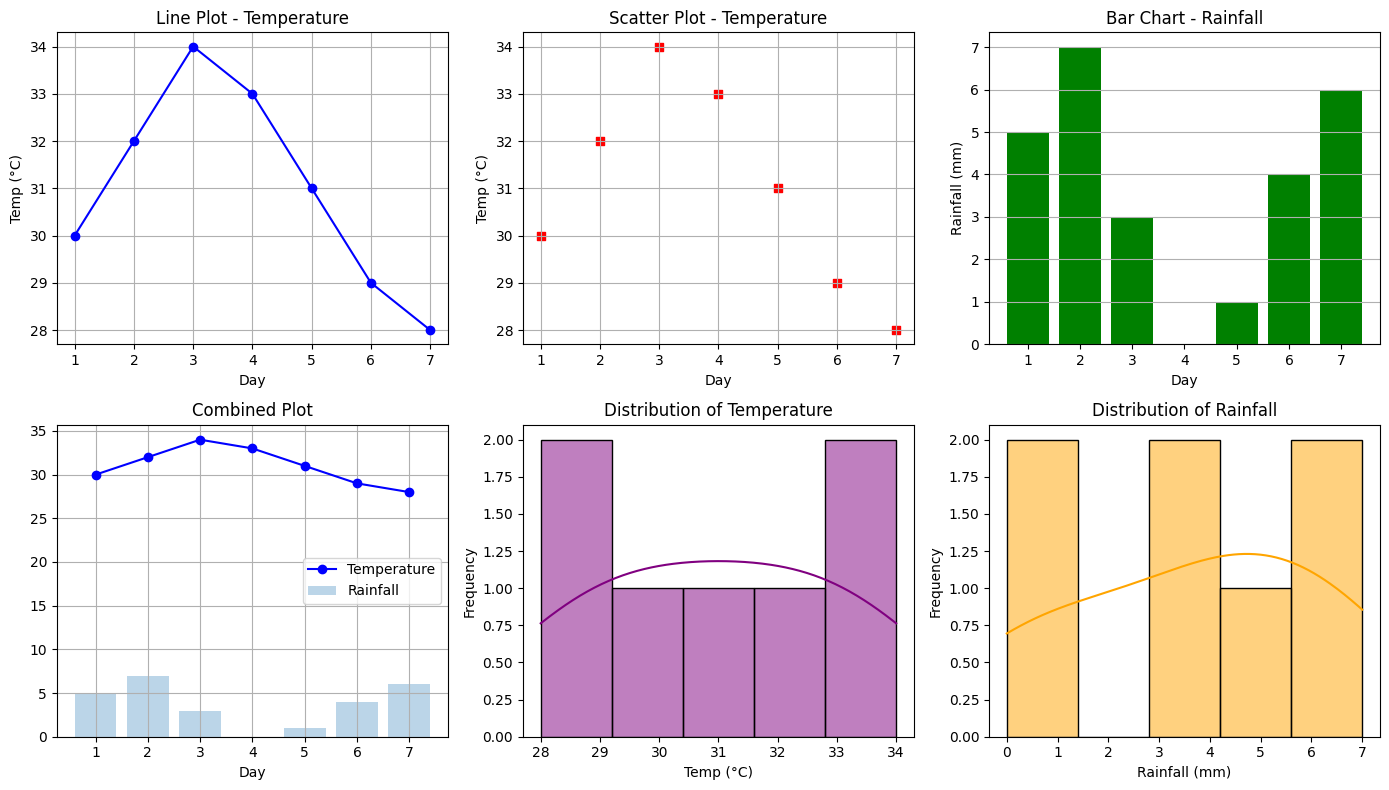

In [9]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import seaborn as sns

# Sample data
days = [1, 2, 3, 4, 5, 6, 7]
temp = [30, 32, 34, 33, 31, 29, 28]
rainfall = [5, 7, 3, 0, 1, 4, 6]

# Create 2x3 subplots (6 graphs now)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# -------- Graph 1: Line Plot --------
axes[0, 0].plot(days, temp, marker='o', color='blue')
axes[0, 0].set_title("Line Plot - Temperature")
axes[0, 0].set_xlabel("Day")
axes[0, 0].set_ylabel("Temp (°C)")
axes[0, 0].grid(True)

# -------- Graph 2: Scatter Plot --------
axes[0, 1].scatter(days, temp, color='red', marker='s')
axes[0, 1].set_title("Scatter Plot - Temperature")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Temp (°C)")
axes[0, 1].grid(True)

# -------- Graph 3: Bar Chart --------
axes[0, 2].bar(days, rainfall, color='green')
axes[0, 2].set_title("Bar Chart - Rainfall")
axes[0, 2].set_xlabel("Day")
axes[0, 2].set_ylabel("Rainfall (mm)")
axes[0, 2].grid(axis='y')

# -------- Graph 4: Combined Plot --------
axes[1, 0].plot(days, temp, marker='o', color='blue', label="Temperature")
axes[1, 0].bar(days, rainfall, alpha=0.3, label="Rainfall")
axes[1, 0].set_title("Combined Plot")
axes[1, 0].set_xlabel("Day")
axes[1, 0].legend()
axes[1, 0].grid(True)

# -------- Graph 5: Distribution Plot (Histogram + KDE) --------
sns.histplot(temp, kde=True, bins=5, ax=axes[1, 1], color="purple")
axes[1, 1].set_title("Distribution of Temperature")
axes[1, 1].set_xlabel("Temp (°C)")
axes[1, 1].set_ylabel("Frequency")

# -------- Graph 6: Distribution Plot for Rainfall --------
sns.histplot(rainfall, kde=True, bins=5, ax=axes[1, 2], color="orange")
axes[1, 2].set_title("Distribution of Rainfall")
axes[1, 2].set_xlabel("Rainfall (mm)")
axes[1, 2].set_ylabel("Frequency")

# Adjust layout
plt.tight_layout()
plt.show()


C:\Users\World\AppData\Local\Temp\ipykernel_10024\3989653516.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].median(), inplace=True)
C:\Users\World\AppData\Local\Temp\ipykernel_10024\3989653516.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For

RMSE: 204.87952430045706
R²: 0.9903921380335949


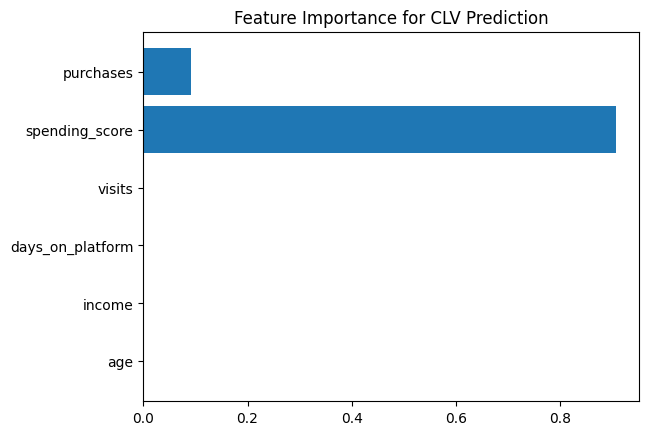

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv(r'C:\Users\World\Downloads\synthetic_clv_training_data.csv')

# Create target variable
df['CLV'] = df['spending_score'] * df['purchases']

# Handle missing values
df['age'].fillna(df['age'].median(), inplace=True)
df['income'].fillna(df['income'].median(), inplace=True)
df['visits'].fillna(df['visits'].median(), inplace=True)

# Features
features = ['age', 'income', 'days_on_platform', 'visits', 'spending_score', 'purchases']
X = df[features]
y = df['CLV']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

# Feature importance
plt.barh(features, model.feature_importances_)
plt.title("Feature Importance for CLV Prediction")
plt.show()

In [4]:
CLV=model.predict([[25,50000,5,2,3,200]])
print(CLV)

[71.6926]


C:\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


C:\Users\World\AppData\Local\Temp\ipykernel_10024\1439959701.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)


(10000, 20)
R² Train: 0.8133
R² Test: 0.7992


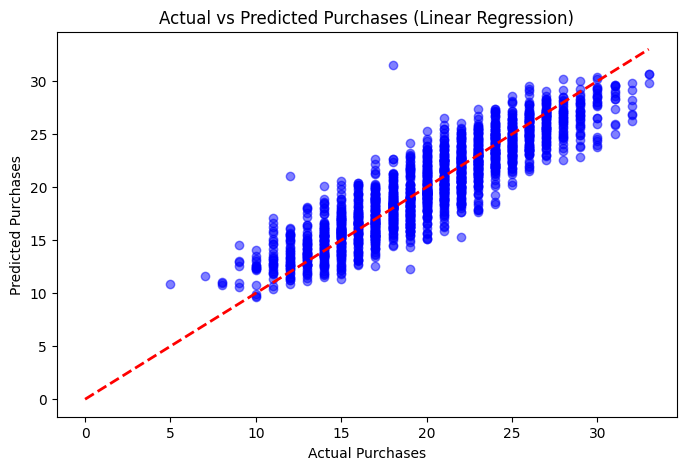

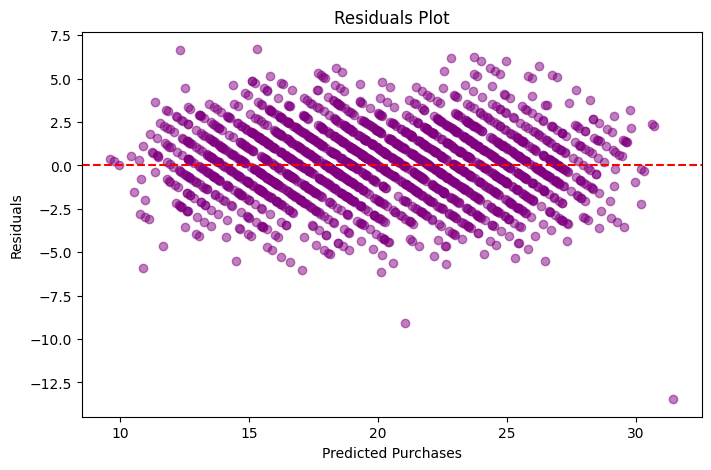

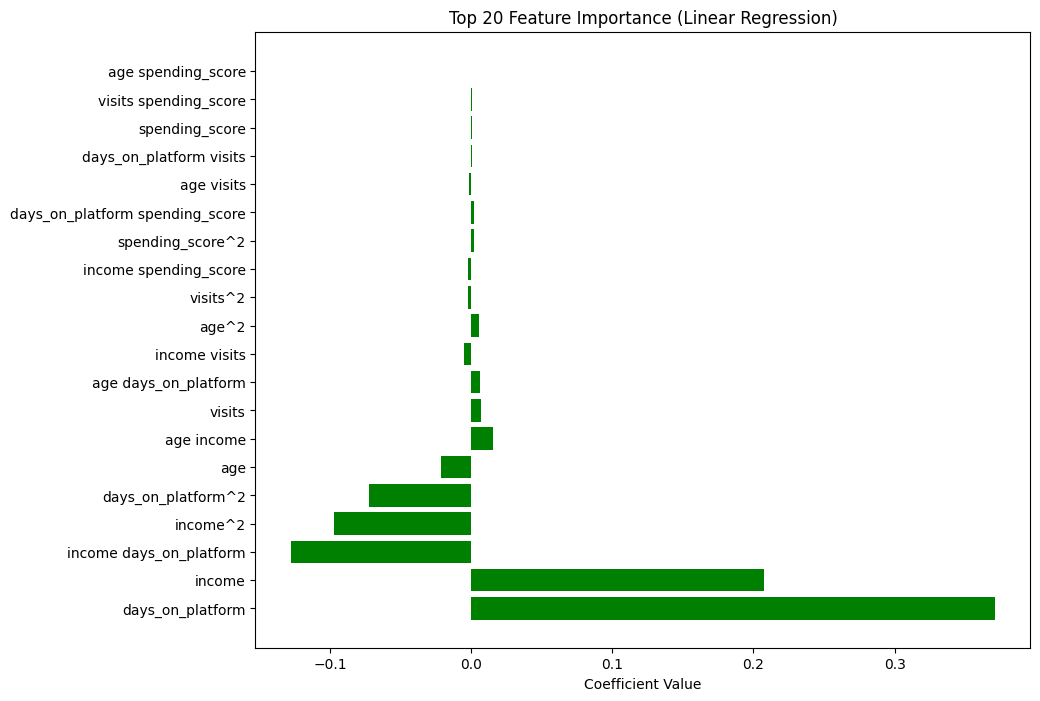

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, cross_val_score

# --- Load Data ---
df = pd.read_csv(r'C:\Users\World\Downloads\synthetic_clv_training_data.csv')

# --- Handle Missing Values ---
numeric_cols = df.select_dtypes(include=np.number).columns
for col in numeric_cols:
    df[col].fillna(df[col].mean(), inplace=True)

# --- Optional: Log-transform target to reduce skewness ---
df['purchases_log'] = np.log1p(df['purchases'])
y = df['purchases_log']

# --- Features ---
X = df.drop(columns=['purchases', 'purchases_log', 'id'])

# --- Feature Engineering: Polynomial + Interaction terms ---
poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
X_poly = poly.fit_transform(X)

# --- Feature Scaling ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_poly)
print(X_scaled.shape)
# --- Train/Test Split ---
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# --- Linear Regression with Ridge (better generalization) ---
model = LinearRegression()
model.fit(X_train, y_train)

# --- Evaluate Model ---
r2_train = model.score(X_train, y_train)
r2_test = model.score(X_test, y_test)
print(f"R² Train: {r2_train:.4f}")
print(f"R² Test: {r2_test:.4f}")

# --- Predictions (convert back from log if needed) ---
y_pred_log = model.predict(X_test)
y_pred = np.expm1(y_pred_log)  # reverse log1p

# --- Plot Actual vs Predicted ---
plt.figure(figsize=(8,5))
plt.scatter(np.expm1(y_test), y_pred, alpha=0.5, color='blue')
plt.plot([0, max(np.expm1(y_test))], [0, max(np.expm1(y_test))], 'r--', lw=2)
plt.xlabel("Actual Purchases")
plt.ylabel("Predicted Purchases")
plt.title("Actual vs Predicted Purchases (Linear Regression)")
plt.show()

# --- Residual Plot ---
residuals = np.expm1(y_test) - y_pred
plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals, alpha=0.5, color='purple')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Purchases")
plt.ylabel("Residuals")
plt.title("Residuals Plot")
plt.show()

# --- Feature Importance ---
feature_names = poly.get_feature_names_out(X.columns)
coef_df = pd.DataFrame({"Feature": feature_names, "Coefficient": model.coef_})
coef_df = coef_df.sort_values(by="Coefficient", key=abs, ascending=False)

plt.figure(figsize=(10,8))
plt.barh(coef_df['Feature'][:20], coef_df['Coefficient'][:20], color='green')  # Top 20 features
plt.xlabel("Coefficient Value")
plt.title("Top 20 Feature Importance (Linear Regression)")
plt.show()


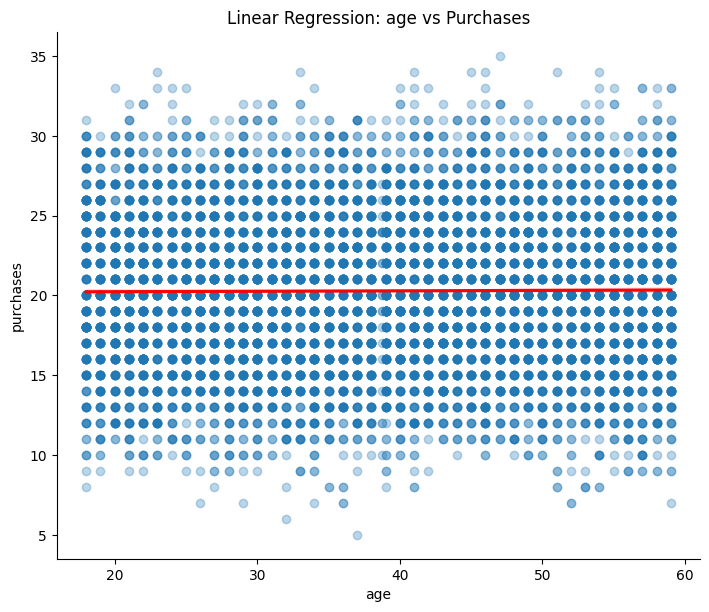

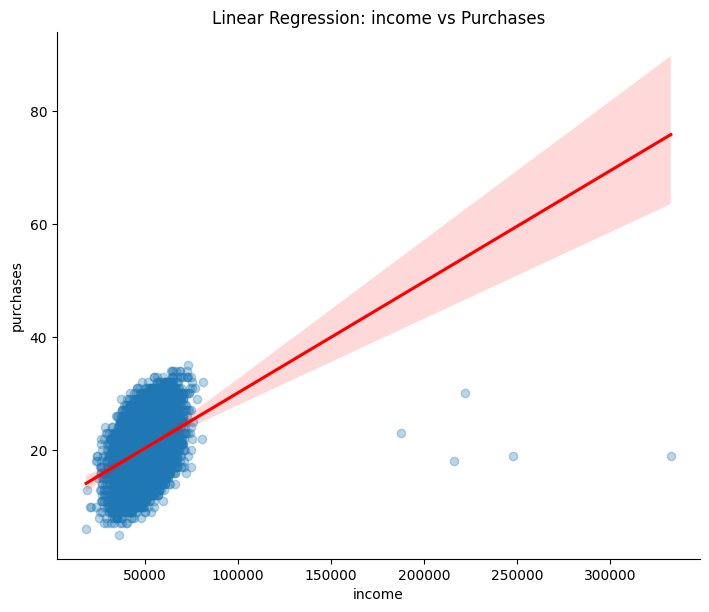

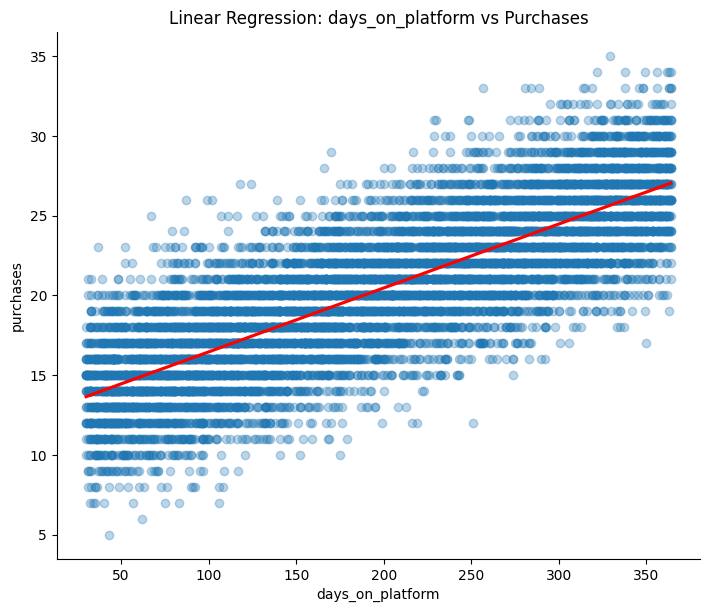

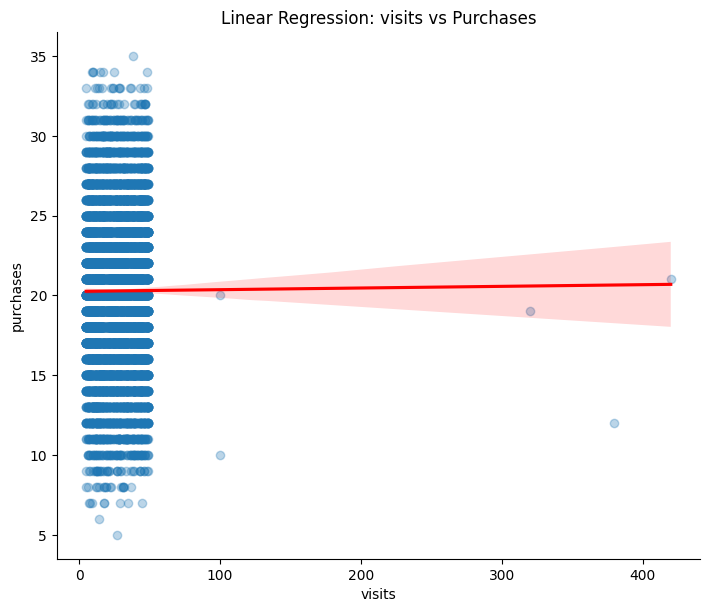

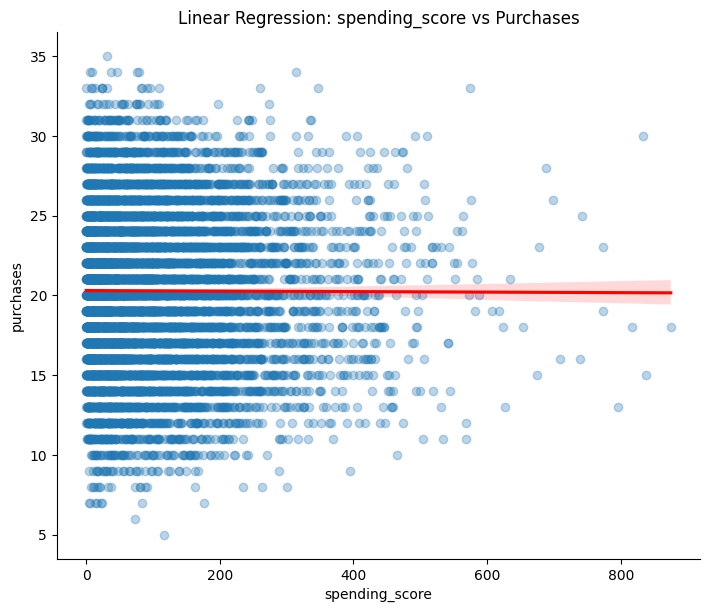

In [14]:
for col in X.columns:
    sns.lmplot(x=col, y='purchases', data=df, 
               height=6, aspect=1.2, 
               scatter_kws={'alpha':0.3}, 
               line_kws={'color':'red'})
    plt.title(f"Linear Regression: {col} vs Purchases")
    plt.show()


C:\Users\World\AppData\Local\Temp\ipykernel_10024\2771522233.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


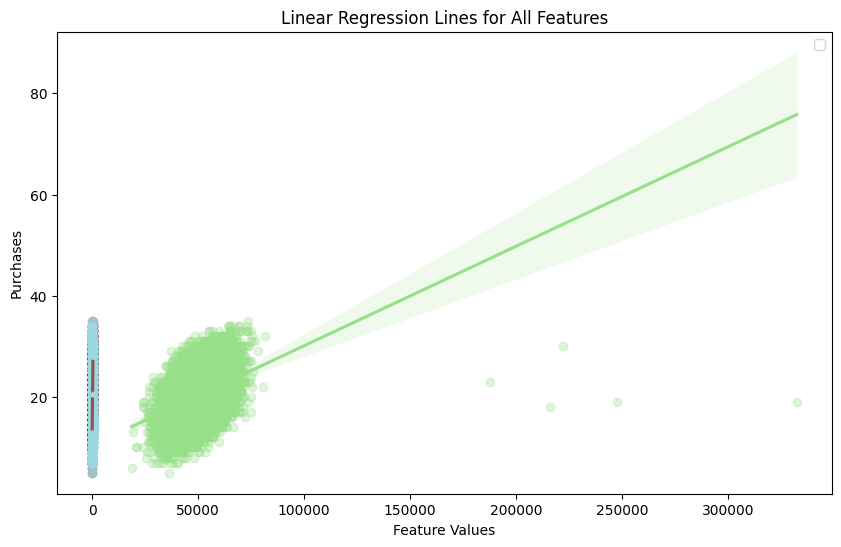

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Colors for each feature
colors = plt.cm.tab20(np.linspace(0, 1, X.shape[1]))

plt.figure(figsize=(10, 6))

# Loop through all original features
for i, col in enumerate(X.columns):
    sns.regplot(x=col, y='purchases', data=df, 
                scatter=False,  # don't show scatter points for each feature
                line_kws={'color': colors[i], 'label': col})

# Optionally, overlay scatter points for target vs all features
for i, col in enumerate(X.columns):
    plt.scatter(df[col], df['purchases'], color=colors[i], alpha=0.3)

plt.xlabel("Feature Values")
plt.ylabel("Purchases")
plt.title("Linear Regression Lines for All Features")
plt.legend()
plt.show()


In [3]:
# ===========================================
# 1. Import required libraries
# ===========================================
import pandas as pd                     # For data handling (loading, cleaning, transforming)
import numpy as np                      # For numerical operations (mean, median, etc.)
from sklearn.model_selection import train_test_split  # For splitting data into training & test sets
from sklearn.linear_model import LinearRegression     # Linear regression model
from sklearn.metrics import r2_score                  # To evaluate model performance
from sklearn.preprocessing import OneHotEncoder       # To convert categorical features into numbers
from sklearn.impute import SimpleImputer              # To handle missing values
from sklearn.compose import ColumnTransformer         # To apply transformations to selected columns
from sklearn.pipeline import Pipeline                 # To chain preprocessing + model

# ===========================================
# 2. Load the dataset
# ===========================================
df = pd.read_csv("C:/Users/World/Downloads/Compressed/clv_data.csv")

# ===========================================
# 3. Drop unnecessary columns
# ===========================================
# "id" is just an identifier, it doesn't help prediction
df = df.drop(columns=["id"])

# ===========================================
# 4. Define features (X) and target (y)
# ===========================================
X = df.drop(columns=["purchases"])   # Independent variables
y = df["purchases"]                  # Dependent variable we want to predict

# ===========================================
# 5. Identify categorical and numeric columns
# ===========================================
categorical_cols = ["gender", "city"]
numeric_cols = [col for col in X.columns if col not in categorical_cols]

# ===========================================
# 6. Preprocessing steps
# ===========================================
# Why? Because machine learning models only work with numbers, 
# we need to encode text and handle missing values.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))  # Fill missing numbers with median
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")), # Fill missing categories with most common value
    ("encoder", OneHotEncoder(handle_unknown="ignore"))   # Convert text to numeric columns
])

# Combine both numeric & categorical pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# ===========================================
# 7. Build the full pipeline (preprocessing + model)
# ===========================================
model = Pipeline(steps=[
    ("preprocessor", preprocessor),      # First do preprocessing
    ("regressor", LinearRegression())    # Then apply Linear Regression
])

# ===========================================
# 8. Train-Test Split
# ===========================================
# Why 80/20? → 80% of data for training, 20% unseen test for evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ===========================================
# 9. Train the model
# ===========================================
model.fit(X_train, y_train)

# ===========================================
# 10. Make predictions
# ===========================================
y_pred = model.predict(X_test)

# ===========================================
# 11. Evaluate the model
# ===========================================
r2 = r2_score(y_test, y_pred)
print("R² Score:", r2)


R² Score: -0.0046539244310948025


In [4]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge

# ===========================================
# 1. Preprocessing stays same as before
# ===========================================

# Numeric pipeline (with scaling now)
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())   # Scale numbers for polynomial expansion
])

# Categorical pipeline stays same
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# ===========================================
# 2. Add polynomial features + Ridge Regression
# ===========================================
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),  # Interaction terms
    ("regressor", Ridge(alpha=1.0))  # Ridge regression for better generalization
])

# ===========================================
# 3. Train-test split and fit
# ===========================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)

# ===========================================
# 4. Predictions and evaluation
# ===========================================
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

print("Improved R² Score:", r2)


Improved R² Score: -0.015567526774709961


In [5]:
from sklearn.ensemble import RandomForestRegressor

# ===========================================
# 1. Preprocessing (same as before, without polynomial)
# ===========================================
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# ===========================================
# 2. Random Forest Model
# ===========================================
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,       # number of trees
        max_depth=15,           # limit depth to avoid overfitting
        random_state=42,
        n_jobs=-1               # use all CPU cores
    ))
])

# ===========================================
# 3. Train-test split and fit
# ===========================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)

# ===========================================
# 4. Predictions and evaluation
# ===========================================
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

print("Random Forest R² Score:", r2)


Random Forest R² Score: -0.04269738275959112


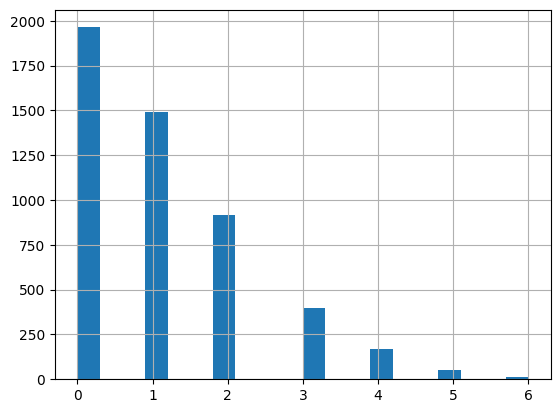

count    5000.000000
mean        1.101000
std         1.181473
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max         6.000000
Name: purchases, dtype: float64
purchases
0    1964
1    1490
2     919
3     400
4     168
5      49
6      10
Name: count, dtype: int64


In [6]:
import matplotlib.pyplot as plt

df["purchases"].hist(bins=20)
plt.show()

print(df["purchases"].describe())
print(df["purchases"].value_counts().head(10))


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Reframe target as binary (purchase or not)
y_binary = (y > 0).astype(int)  # 1 = purchased, 0 = no purchase

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y_binary, test_size=0.2, random_state=42)

# 3. Random Forest Classifier
clf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

# 4. Train
clf.fit(X_train, y_train)

# 5. Predictions
y_pred = clf.predict(X_test)

# 6. Evaluation
acc = accuracy_score(y_test, y_pred)
print("Binary Classification Accuracy:", acc)
print(classification_report(y_test, y_pred))


Binary Classification Accuracy: 0.558
              precision    recall  f1-score   support

           0       0.38      0.17      0.24       401
           1       0.60      0.82      0.69       599

    accuracy                           0.56      1000
   macro avg       0.49      0.49      0.46      1000
weighted avg       0.51      0.56      0.51      1000

